In [2]:
import numpy as np
from scipy.integrate import trapezoid
import matplotlib.pyplot as plt
from scipy.optimize import fsolve

In [3]:
#parameters
Hs = 6.0       # Significant wave height [m]
g = 9.81       # Gravitational acceleration [m/s^2]
s0p = 0.05     # Chosen deep-water wave steepness Hs / lambda_0p [-] (typical steep wind sea: 0.035 - 0.040)

# Calculate peak period Tp [s]
Tp = np.sqrt((2 * np.pi * Hs) / (g * s0p))

# Equivalent dimensionless steepness ka = pi * s0p (Lecture 3, Slide 3 & 9)
ka = np.pi * s0p

print(f"Peak period Tp = {Tp:.2f} s")
print(f"Steepness ka   = {ka:.3f}")

Peak period Tp = 8.77 s
Steepness ka   = 0.157


A_gamma         = 0.65734
m0              = 2.2552 m^2  (target Hs^2/16 = 2.2500 m^2)
Check Hs (4√m0) = 6.007 m
T_m-1,0         = 8.86 s
T_m01           = 8.19 s
T_m02 (T_m)     = 7.67 s


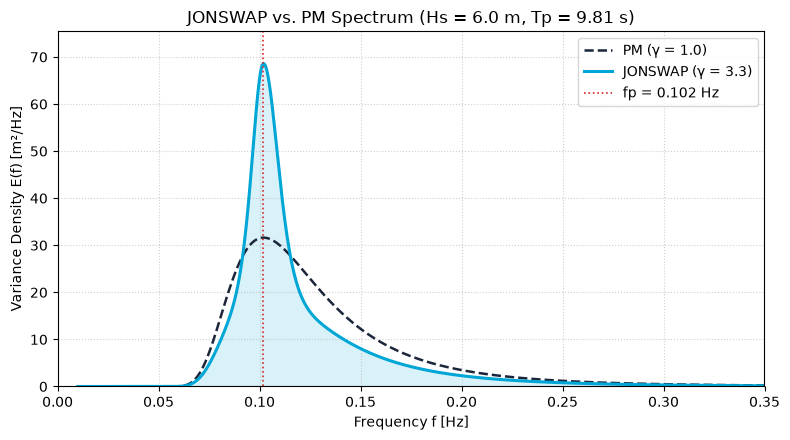

Peak frequency fp = 0.102 Hz


In [13]:
fp = 1.0 / Tp   # Peak frequency [Hz]

# JONSWAP parameters (Lecture 5, slide 12)
gamma = 3.3
sigma_a = 0.07  # for f <= fp
sigma_b = 0.09  # for f > fp

# 2. Frequency grid (avoid f = 0 to prevent division by zero)
f = np.linspace(0.01, 1.0, 10000)
sigma = np.where(f <= fp, sigma_a, sigma_b)

# 3. Pierson-Moskowitz spectrum E_PM(f)
E_PM = (5.0 / 16.0) * (Hs**2) * (fp**4) * (f**(-5)) * np.exp(-1.25 * (fp / f)**4)

# 4. JONSWAP spectrum E(f) with normalizing factor A_gamma
A_gamma = 1.0 - 0.287 * np.log(gamma)
peak_enhancement = gamma ** np.exp(-((f - fp)**2) / (2.0 * (sigma**2) * (fp**2)))
E = A_gamma * E_PM * peak_enhancement

# 5. Compute spectral moments
m_minus1 = trapezoid(f**(-1) * E, f)
m0 = trapezoid(E, f)
m1 = trapezoid(f**1 * E, f)
m2 = trapezoid(f**2 * E, f)

# 6. Compute characteristic wave periods
Tm_10 = m_minus1 / m0        # Energy period T_{m-1,0}
Tm01 = m0 / m1               # Mean spectral period T_{m01}
Tm02 = np.sqrt(m0 / m2)      # Mean zero-crossing period T_{m02} (T_z / T_m)

print(f"A_gamma         = {A_gamma:.5f}")
print(f"m0              = {m0:.4f} m^2  (target Hs^2/16 = {Hs**2 / 16:.4f} m^2)")
print(f"Check Hs (4√m0) = {4 * np.sqrt(m0):.3f} m")
print(f"T_m-1,0         = {Tm_10:.2f} s")
print(f"T_m01           = {Tm01:.2f} s")
print(f"T_m02 (T_m)     = {Tm02:.2f} s")

# 7. Plot both PM and JONSWAP spectra for comparison
plt.figure(figsize=(8, 4.5))
plt.plot(f, E_PM, color="#1b263b", linestyle="--", linewidth=1.8, label="PM (γ = 1.0)")
plt.plot(f, E, color="#00a6d6", linewidth=2.2, label=f"JONSWAP (γ = {gamma})")
plt.fill_between(f, E, alpha=0.15, color="#00a6d6")
plt.axvline(fp, color="#d62728", linestyle=":", linewidth=1.2, label=f"fp = {fp:.3f} Hz")

plt.xlim(0, 0.35)
plt.ylim(0, np.max(E) * 1.1)
plt.xlabel("Frequency f [Hz]")
plt.ylabel("Variance Density E(f) [m²/Hz]")
plt.title(f"JONSWAP vs. PM Spectrum (Hs = {Hs} m, Tp = {Tp} s)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Peak frequency fp = {fp:.3f} Hz")

In [5]:
h = 20.0  # Water depth [m]

def local_wave_steepness(Hs, T, h):
    omega = 2 * np.pi / T
    # Solve omega^2 = g * k * tanh(k * h) using deep-water k0 as initial guess
    k = fsolve(lambda k: omega**2 - g * k * np.tanh(k * h), omega**2 / g)[0]
    L = 2 * np.pi / k
    return Hs / L, L, k

for name, T in [("Tp", Tp), ("T_m-1,0", Tm_10), ("T_m01", Tm01), ("T_m02", Tm02)]:
    s, L, k = local_wave_steepness(Hs, T, h)
    print(f"{name:7s} = {T:.2f} s  ->  L = {L:6.2f} m,  s = {s:.4f}")

Tp      = 8.77 s  ->  L = 101.42 m,  s = 0.0592
T_m-1,0 = 7.92 s  ->  L =  87.46 m,  s = 0.0686
T_m01   = 7.32 s  ->  L =  77.45 m,  s = 0.0775
T_m02   = 6.86 s  ->  L =  69.59 m,  s = 0.0862


eta(t):   std = 1.501 m  |  4*std (Hs check) = 6.003 m  |  max = 4.79 m
u(0, t):  u_rms = 1.386 m/s  |  max = 4.77 m/s


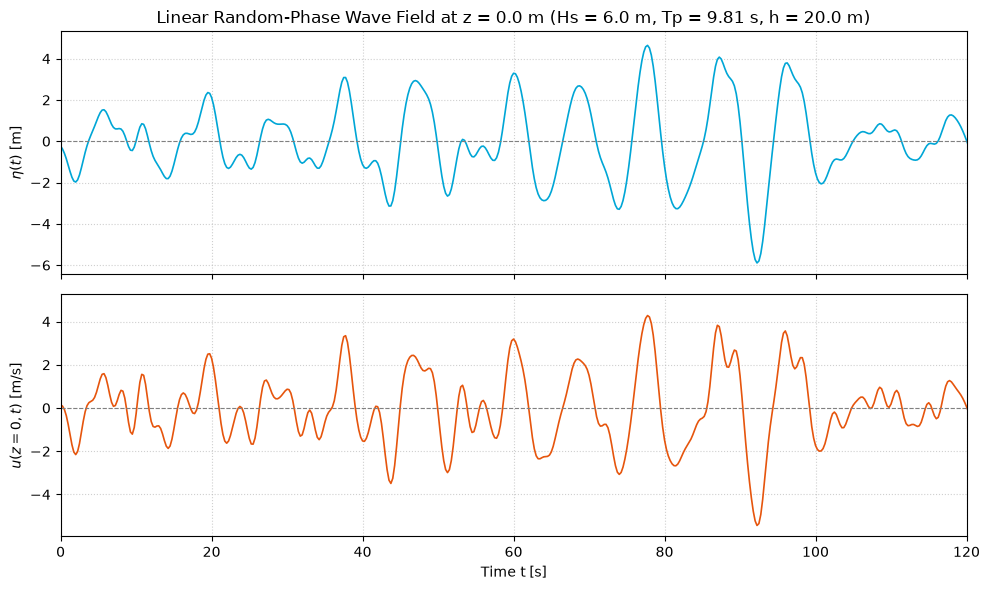

In [11]:
# 1. Wave and site parameters
Hs = 6.0        # Significant wave height [m]
Tp = 9.81       # Peak period [s]
fp = 1.0 / Tp   # Peak frequency [Hz]
gamma = 3.3     # JONSWAP peak enhancement factor
h = 20.0        # Water depth [m]
g = 9.81        # Gravity [m/s^2]
z = 0.0         # Evaluation elevation [m] (mean water level)

# 2. Time and frequency grids
D = 1200.0      # Record duration [s] (20 minutes)
dt = 0.25       # Time step [s]
t = np.arange(0, D, dt)

df = 1.0 / D    # Frequency resolution [Hz] (prevents repetition within D)
f = np.arange(0.02, 0.5, df)  # Frequency array [Hz] (avoid f = 0)
omega = 2 * np.pi * f

# 3. JONSWAP variance density spectrum E(f) (Lecture 5)
sigma = np.where(f <= fp, 0.07, 0.09)
A_gamma = 1.0 - 0.287 * np.log(gamma)
E_PM = (5.0 / 16.0) * (Hs**2) * (fp**4) * (f**(-5)) * np.exp(-1.25 * (fp / f)**4)
E = A_gamma * E_PM * (gamma ** np.exp(-((f - fp)**2) / (2.0 * (sigma**2) * (fp**2))))

# 4. Solve linear dispersion relation k(f) for every frequency component
k = np.array([
    fsolve(lambda ki: w**2 - g * ki * np.tanh(ki * h), w**2 / g)[0]
    for w in omega
])

# 5. Linear transfer function for horizontal velocity u at elevation z
H_u = omega * np.cosh(k * (z + h)) / np.sinh(k * h)

# 6. Random-phase synthesis
rng = np.random.default_rng(42)            # Fixed seed for reproducibility
a = np.sqrt(2.0 * E * df)                  # Component amplitudes [m]
alpha = rng.uniform(0, 2 * np.pi, len(f))  # Random phases in [0, 2*pi)

# Vectorized summation over all frequency components
phase = omega[:, None] * t[None, :] + alpha[:, None]
eta = np.sum(a[:, None] * np.cos(phase), axis=0)
u = np.sum((H_u * a)[:, None] * np.cos(phase), axis=0)

# 7. Sanity checks
print(f"eta(t):   std = {np.std(eta):.3f} m  |  4*std (Hs check) = {4*np.std(eta):.3f} m  |  max = {np.max(eta):.2f} m")
print(f"u(0, t):  u_rms = {np.std(u):.3f} m/s  |  max = {np.max(u):.2f} m/s")

# 8. Plot first 120 seconds of both time series
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

ax1.plot(t, eta, color="#00a6d6", linewidth=1.2)
ax1.axhline(0, color="gray", linewidth=0.8, linestyle="--")
ax1.set_ylabel(r"$\eta(t)$ [m]")
ax1.set_title(f"Linear Random-Phase Wave Field at z = {z} m (Hs = {Hs} m, Tp = {Tp} s, h = {h} m)")
ax1.grid(True, linestyle=":", alpha=0.6)

ax2.plot(t, u, color="#e6550d", linewidth=1.2)
ax2.axhline(0, color="gray", linewidth=0.8, linestyle="--")
ax2.set_xlabel("Time t [s]")
ax2.set_ylabel(r"$u(z=0, t)$ [m/s]")
ax2.set_xlim(0, 120)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()